In [1]:
import sys
print(sys.executable)

C:\ProgramData\anaconda3\envs\mall_pyspark\python.exe


In [2]:
import os, sys

# Silence the "Missing Python executable 'python3'" warning
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

from pyspark.sql import SparkSession
spark = SparkSession.builder \
    .appName("mall") \
    .config("spark.ui.showConsoleProgress", "false") \
    .getOrCreate()

# Downgrade Spark's chatty WARN logs
spark.sparkContext.setLogLevel("ERROR")

print("Spark:", spark.version)
print(spark.range(5).collect())
spark.stop()

Spark: 3.5.5
[Row(id=0), Row(id=1), Row(id=2), Row(id=3), Row(id=4)]


In [4]:
import os
print("Working dir:", os.getcwd())
print("CSV exists :", os.path.exists("data/Mall_Customers.csv"))

Working dir: D:\Datamites Data Engineering\project_3_mall_customers (pyspark)
CSV exists : True


In [5]:
import os, sys

# Prevent "Missing Python executable 'python3'" warning
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

from pyspark.sql import SparkSession
from pyspark.sql.functions import (
    col, count, mean, stddev, min, max, median,
    round as sround, when, desc, asc
)
from pyspark.sql.types import IntegerType
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.clustering import KMeans

spark = SparkSession.builder \
    .appName("MallCustomers_SpendingScore_Analysis") \
    .config("spark.ui.showConsoleProgress", "false") \
    .getOrCreate()

# Downgrade Spark's chatty WARN logs to ERROR
spark.sparkContext.setLogLevel("ERROR")

print("PySpark :", spark.version)
print("Python  :", sys.version.split()[0])

PySpark : 3.5.5
Python  : 3.11.18


In [6]:
# Load the csv

CSV_PATH = "data/Mall_Customers.csv"

df_raw = spark.read \
    .option("header", "true") \
    .option("inferSchema", "true") \
    .csv(CSV_PATH)

print("Rows   :", df_raw.count())
print("Columns:", len(df_raw.columns))
df_raw.printSchema()
df_raw.show(5, truncate=False)

Rows   : 200
Columns: 5
root
 |-- CustomerID: integer (nullable = true)
 |-- Genre: string (nullable = true)
 |-- Age: integer (nullable = true)
 |-- Annual Income (k$): integer (nullable = true)
 |-- Spending Score (1-100): integer (nullable = true)

+----------+------+---+------------------+----------------------+
|CustomerID|Genre |Age|Annual Income (k$)|Spending Score (1-100)|
+----------+------+---+------------------+----------------------+
|1         |Male  |19 |15                |39                    |
|2         |Male  |21 |15                |81                    |
|3         |Female|20 |16                |6                     |
|4         |Female|23 |16                |77                    |
|5         |Female|31 |17                |40                    |
+----------+------+---+------------------+----------------------+
only showing top 5 rows



In [7]:
# Clean and rename columns
df = df_raw \
    .withColumnRenamed("CustomerID", "customer_id") \
    .withColumnRenamed("Genre", "genre") \
    .withColumnRenamed("Age", "age") \
    .withColumnRenamed("Annual Income (k$)", "annual_income_k") \
    .withColumnRenamed("Spending Score (1-100)", "spending_score") \
    .withColumn("customer_id",    col("customer_id").cast(IntegerType())) \
    .withColumn("age",            col("age").cast(IntegerType())) \
    .withColumn("annual_income_k", col("annual_income_k").cast(IntegerType())) \
    .withColumn("spending_score", col("spending_score").cast(IntegerType()))

df.printSchema()
df.show(5)

root
 |-- customer_id: integer (nullable = true)
 |-- genre: string (nullable = true)
 |-- age: integer (nullable = true)
 |-- annual_income_k: integer (nullable = true)
 |-- spending_score: integer (nullable = true)

+-----------+------+---+---------------+--------------+
|customer_id| genre|age|annual_income_k|spending_score|
+-----------+------+---+---------------+--------------+
|          1|  Male| 19|             15|            39|
|          2|  Male| 21|             15|            81|
|          3|Female| 20|             16|             6|
|          4|Female| 23|             16|            77|
|          5|Female| 31|             17|            40|
+-----------+------+---+---------------+--------------+
only showing top 5 rows



In [8]:
# data quality check
from pyspark.sql.functions import isnan, when, count as _count

null_counts = df.select([
    _count(when(col(c).isNull(), c)).alias(c) for c in df.columns
])
print("Null counts per column:")
null_counts.show()

print("Distinct customer IDs:", df.select("customer_id").distinct().count())
print("Total rows          :", df.count())

df.describe().show()

Null counts per column:
+-----------+-----+---+---------------+--------------+
|customer_id|genre|age|annual_income_k|spending_score|
+-----------+-----+---+---------------+--------------+
|          0|    0|  0|              0|             0|
+-----------+-----+---+---------------+--------------+

Distinct customer IDs: 200
Total rows          : 200
+-------+------------------+------+-----------------+-----------------+------------------+
|summary|       customer_id| genre|              age|  annual_income_k|    spending_score|
+-------+------------------+------+-----------------+-----------------+------------------+
|  count|               200|   200|              200|              200|               200|
|   mean|             100.5|  NULL|            38.85|            60.56|              50.2|
| stddev|57.879184513951124|  NULL|13.96900733155888|26.26472116527124|25.823521668370173|
|    min|                 1|Female|               18|               15|                 1|
|    max| 

In [9]:
# Overall Spending Score statistics
df.select(
    count("spending_score").alias("count"),
    sround(mean("spending_score"),   2).alias("mean"),
    median("spending_score").alias("median"),
    sround(stddev("spending_score"), 2).alias("std_dev"),
    min("spending_score").alias("min"),
    max("spending_score").alias("max")
).show()

+-----+----+------+-------+---+---+
|count|mean|median|std_dev|min|max|
+-----+----+------+-------+---+---+
|  200|50.2|  50.0|  25.82|  1| 99|
+-----+----+------+-------+---+---+



In [10]:
# Spending Score by Genre
by_genre = df.groupBy("genre").agg(
    count("*").alias("n_customers"),
    sround(mean("spending_score"), 2).alias("avg_ss"),
    sround(stddev("spending_score"), 2).alias("std_ss"),
    min("spending_score").alias("min_ss"),
    max("spending_score").alias("max_ss")
).orderBy("genre")
by_genre.show()

+------+-----------+------+------+------+------+
| genre|n_customers|avg_ss|std_ss|min_ss|max_ss|
+------+-----------+------+------+------+------+
|Female|        112| 51.53| 24.11|     5|    99|
|  Male|         88| 48.51|  27.9|     1|    97|
+------+-----------+------+------+------+------+



In [12]:
# Spending Score bands (Low / Medium / High)
df_banded = df.withColumn(
    "ss_band",
    when(col("spending_score") <= 33, "Low (1-33)")
    .when(col("spending_score") <= 66, "Medium (34-66)")
    .otherwise("High (67-100)")
)

df_banded.groupBy("ss_band").agg(
    count("*").alias("customers"),
    sround(mean("annual_income_k"), 2).alias("avg_income_k"),
    sround(mean("age"), 2).alias("avg_age"),
    sround(mean("spending_score"), 2).alias("avg_ss")
).orderBy("ss_band").show()

+--------------+---------+------------+-------+------+
|       ss_band|customers|avg_income_k|avg_age|avg_ss|
+--------------+---------+------------+-------+------+
| High (67-100)|       57|       66.07|  30.18| 82.35|
|    Low (1-33)|       49|        67.0|  42.88| 15.31|
|Medium (34-66)|       94|       53.86|  42.01| 48.89|
+--------------+---------+------------+-------+------+



In [13]:
# Spending Score by age group
df_age = df.withColumn(
    "age_group",
    when(col("age") < 25, "18-24")
    .when(col("age") < 35, "25-34")
    .when(col("age") < 45, "35-44")
    .when(col("age") < 55, "45-54")
    .otherwise("55+")
)

by_age = df_age.groupBy("age_group").agg(
    count("*").alias("n_customers"),
    sround(mean("spending_score"), 2).alias("avg_ss"),
    sround(mean("annual_income_k"), 2).alias("avg_income_k")
).orderBy("age_group")
by_age.show()

+---------+-----------+------+------------+
|age_group|n_customers|avg_ss|avg_income_k|
+---------+-----------+------+------------+
|    18-24|         35| 56.26|       44.66|
|    25-34|         54| 63.17|       71.15|
|    35-44|         42| 49.43|       66.81|
|    45-54|         39| 36.23|       58.64|
|      55+|         30| 39.03|        53.8|
+---------+-----------+------+------------+



In [14]:
# Correlations (income vs spending, age vs spending)
corr_income_ss = df.stat.corr("annual_income_k", "spending_score")
corr_age_ss    = df.stat.corr("age", "spending_score")
corr_age_inc   = df.stat.corr("age", "annual_income_k")

print(f"Correlation  Annual Income vs Spending Score : {corr_income_ss:+.4f}")
print(f"Correlation  Age           vs Spending Score : {corr_age_ss:+.4f}")
print(f"Correlation  Age           vs Annual Income  : {corr_age_inc:+.4f}")

Correlation  Annual Income vs Spending Score : +0.0099
Correlation  Age           vs Spending Score : -0.3272
Correlation  Age           vs Annual Income  : -0.0124


In [15]:
# KMeans customer segmentation (k=5)
assembler = VectorAssembler(
    inputCols=["annual_income_k", "spending_score"],
    outputCol="features"
)
df_feat = assembler.transform(df)

kmeans = KMeans(featuresCol="features", k=5, seed=42)
model  = kmeans.fit(df_feat)
df_clusters = model.transform(df_feat)

cluster_summary = df_clusters.groupBy("prediction").agg(
    count("*").alias("n_customers"),
    sround(mean("annual_income_k"), 1).alias("avg_income_k"),
    sround(mean("spending_score"), 1).alias("avg_ss"),
    sround(mean("age"), 1).alias("avg_age")
).orderBy("prediction")
cluster_summary.show()

+----------+-----------+------------+------+-------+
|prediction|n_customers|avg_income_k|avg_ss|avg_age|
+----------+-----------+------------+------+-------+
|         0|         35|        88.2|  17.1|   41.1|
|         1|         81|        55.3|  49.5|   42.7|
|         2|         23|        26.3|  20.9|   45.2|
|         3|         22|        25.7|  79.4|   25.3|
|         4|         39|        86.5|  82.1|   32.7|
+----------+-----------+------------+------+-------+



In [16]:
# Convert to Pandas for plotting

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

pdf          = df.toPandas()
pdf_clusters = df_clusters.select(
    "annual_income_k", "spending_score", "prediction"
).toPandas()

print("Rows in pandas:", len(pdf))

Rows in pandas: 200


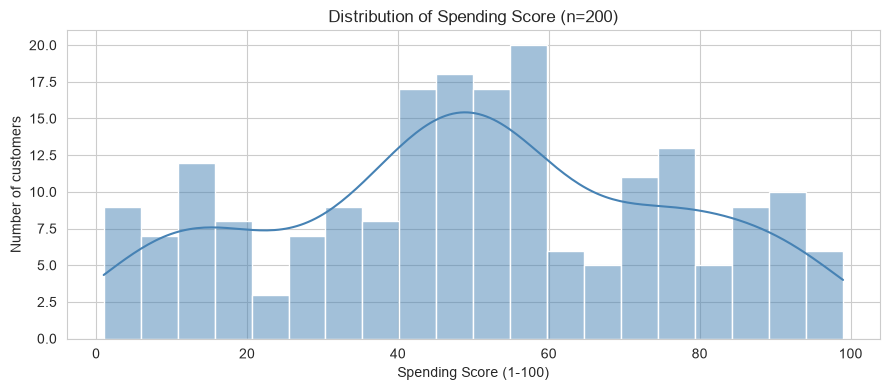

In [17]:
# Chart: Distribution of Spending Score
plt.figure(figsize=(9, 4))
sns.histplot(pdf["spending_score"], bins=20, kde=True, color="steelblue")
plt.title("Distribution of Spending Score (n=200)")
plt.xlabel("Spending Score (1-100)")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()

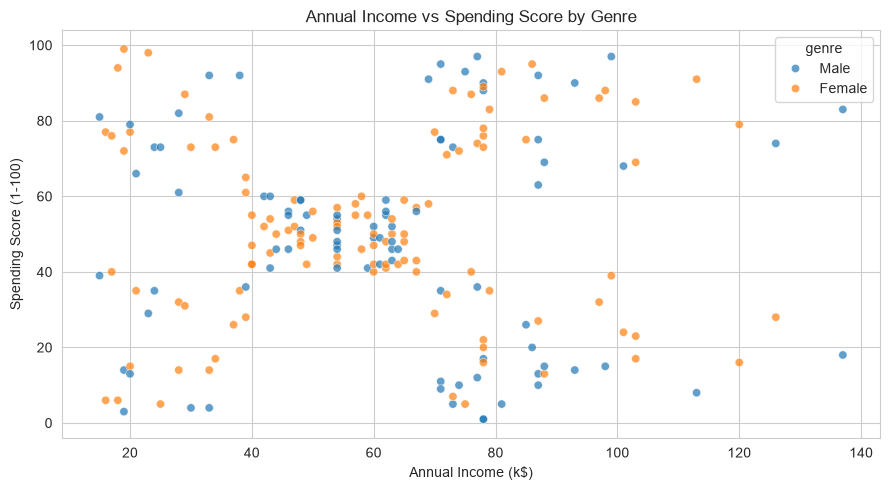

In [18]:
# Chart: Income vs Spending Score
plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=pdf, x="annual_income_k", y="spending_score",
    hue="genre", alpha=0.7
)
plt.title("Annual Income vs Spending Score by Genre")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.tight_layout()
plt.show()

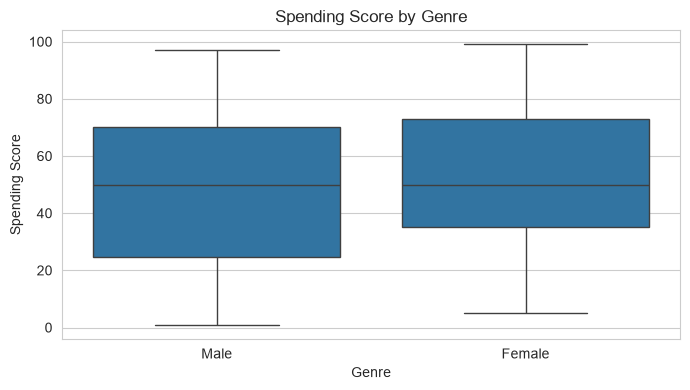

In [19]:
# Chart: Spending Score by Genre (boxplot)
plt.figure(figsize=(7, 4))
sns.boxplot(data=pdf, x="genre", y="spending_score")
plt.title("Spending Score by Genre")
plt.xlabel("Genre")
plt.ylabel("Spending Score")
plt.tight_layout()
plt.show()

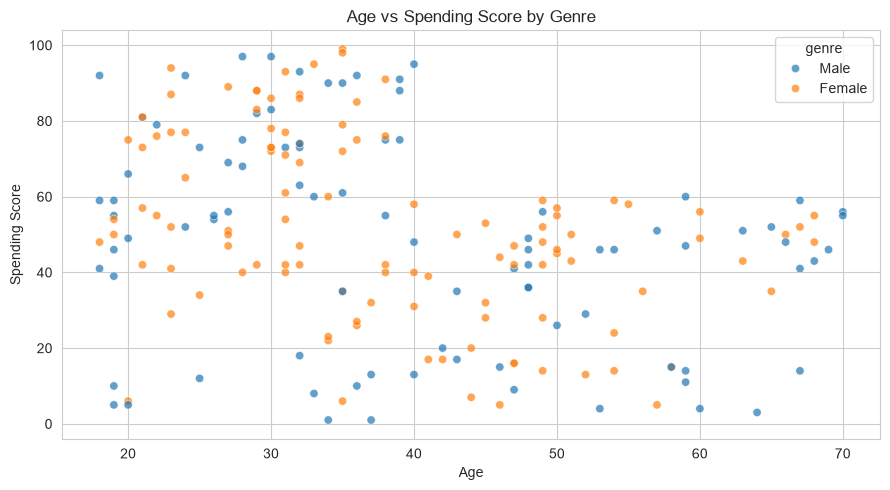

In [20]:
# Chart: Age vs Spending Score
plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=pdf, x="age", y="spending_score",
    hue="genre", alpha=0.7
)
plt.title("Age vs Spending Score by Genre")
plt.xlabel("Age")
plt.ylabel("Spending Score")
plt.tight_layout()
plt.show()

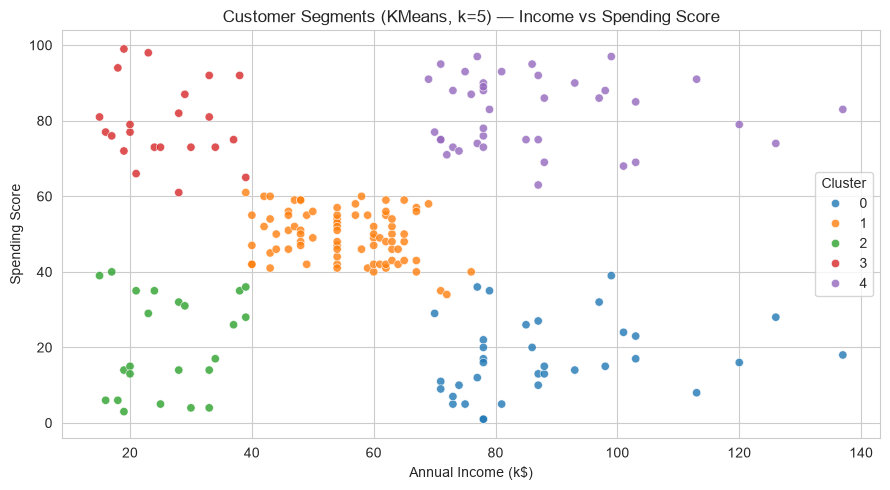

In [21]:
# Chart: KMeans customer segments
plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=pdf_clusters,
    x="annual_income_k", y="spending_score",
    hue="prediction", palette="tab10", alpha=0.8
)
plt.title("Customer Segments (KMeans, k=5) — Income vs Spending Score")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

In [22]:
# Saving summary CSVs to outputs/ for the Word report
os.makedirs("outputs", exist_ok=True)

by_genre.toPandas().to_csv("outputs/ss_by_genre.csv", index=False)
by_age.toPandas().to_csv("outputs/ss_by_age_group.csv", index=False)
cluster_summary.toPandas().to_csv("outputs/kmeans_cluster_summary.csv", index=False)
pdf.to_csv("outputs/cleaned_mall_customers.csv", index=False)
pdf_clusters.to_csv("outputs/kmeans_segments.csv", index=False)

print("Saved to outputs/:", os.listdir("outputs"))

Saved to outputs/: ['cleaned_mall_customers.csv', 'kmeans_cluster_summary.csv', 'kmeans_segments.csv', 'ss_by_age_group.csv', 'ss_by_genre.csv']


In [23]:
spark.stop()
print("Spark session stopped.")

Spark session stopped.
